# 02 · Klassische Modelle

Rollierender Backtest: 45 Ursprünge im Abstand von 8 Tagen über das letzte Jahr, Horizont 24 h und 7 Tage. Erzeugt mit `python -m src.backtest`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from src.report import COLORS, MODELS, INK, MUTED, BLUES, DAYS
from src.backtest import RESULTS

/Users/p.schmidt-petter/Desktop/dev/dev/pedestrian_traffic_forecast/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
fc = pd.read_parquet(RESULTS / 'forecasts.parquet')
fc['model'] = fc['model'].astype(str)
metrics = pd.read_parquet(RESULTS / 'metrics.parquet')
classic = ['SeasonalNaive', 'MSTL-ETS', 'Prophet', 'LightGBM', 'LightGBM-tuned']
metrics[metrics.model.isin(classic)].groupby(['horizon', 'model'])[['MASE', 'sMAPE', 'Coverage80']].mean().round(3)

MASE   sMAPE  Coverage80
horizon model                                    
24      LightGBM        0.711  16.606      70.468
        LightGBM-tuned  0.657  15.937      68.473
        MSTL-ETS        1.233  23.021      86.269
        Prophet         1.098  23.308      83.252
        SeasonalNaive   1.016  24.495      87.673
168     LightGBM        0.769  18.790      69.168
        LightGBM-tuned  0.725  17.874      69.670
        MSTL-ETS        1.303  26.472      96.402
        Prophet         1.019  22.964      83.734
        SeasonalNaive   1.012  24.587      87.222

## Verteilung der Fensterfehler

Der Mittelwert versteckt, wie oft ein Modell danebenliegt. Ausreißerwochen (Feiertage, Großevents) dominieren die Rangfolge.

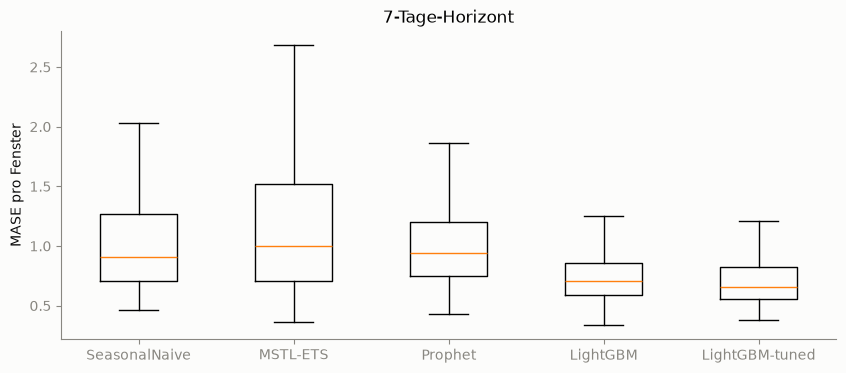

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
d = metrics[(metrics.horizon == 168) & metrics.model.isin(classic)]
ax.boxplot([d[d.model == m].MASE for m in classic], showfliers=False)
ax.set_xticks(range(1, len(classic) + 1), classic)
ax.set(ylabel='MASE pro Fenster', title='7-Tage-Horizont');

## LightGBM: Tuning und Features

Optuna-Suche (50 Trials je Horizont) auf 10 Wochen vor dem ersten Backtest-Ursprung, Early Stopping auf dieser Validierung. Die Ablation trennt den Effekt von Tuning und neuen Features.

In [4]:
from src.report import tuning_table
from IPython.display import Markdown
Markdown(tuning_table(RESULTS / 'tuning.json'))

| Variante | MASE 24 h | MASE 7 d |
|---|---|---|
| v1 | 0.731 | 0.814 |
| v1 + Features | 0.725 | 0.838 |
| Tuning | 0.700 | 0.770 |
| Tuning + Features | 0.680 | 0.774 |

In [5]:
import json
pd.DataFrame(json.loads((RESULTS / 'lgb_params.json').read_text())).rename(columns=lambda h: f'h={h}')

,h=24,h=168
objective,l1,l1
target,log,log
learning_rate,0.078808,0.061825
num_leaves,26,27
min_child_samples,360,77
colsample_bytree,0.452779,0.306386
subsample,0.887531,0.873276
reg_lambda,0.044663,0.073039
subsample_freq,1,1
num_rounds,1948,1071


## LightGBM-tuned: was das globale Modell nutzt

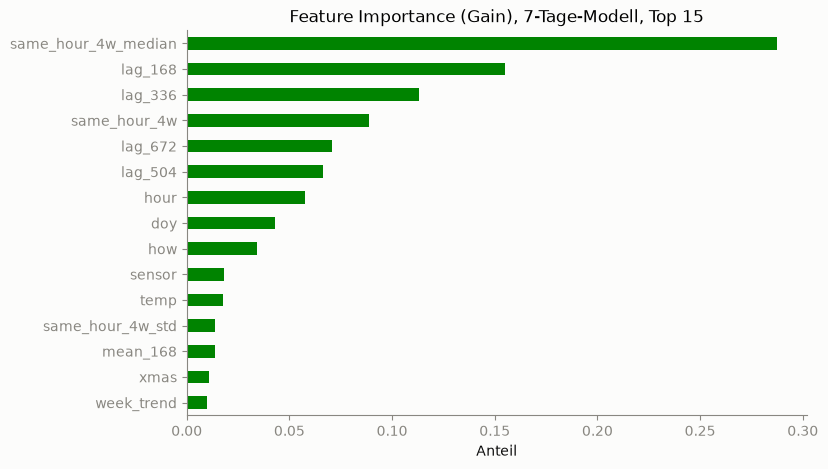

In [6]:
from src.features import build_panel, lgb_features
from src.models import lgb_config, lgb_fit, lgb_prepare

cfg = lgb_config(tuned=True)[168]
df, cols, target_cols = lgb_features(lgb_prepare(build_panel()), 168, extended=True)
fit = df[~df.imputed].dropna(subset=target_cols)
booster = lgb_fit(fit, cols, cfg)
imp = pd.Series(booster.feature_importance('gain'), cols).sort_values().tail(15)
ax = (imp / imp.sum()).plot.barh(figsize=(8, 5), color=COLORS['LightGBM-tuned'])
ax.set(title='Feature Importance (Gain), 7-Tage-Modell, Top 15', xlabel='Anteil');

## Beispielwoche

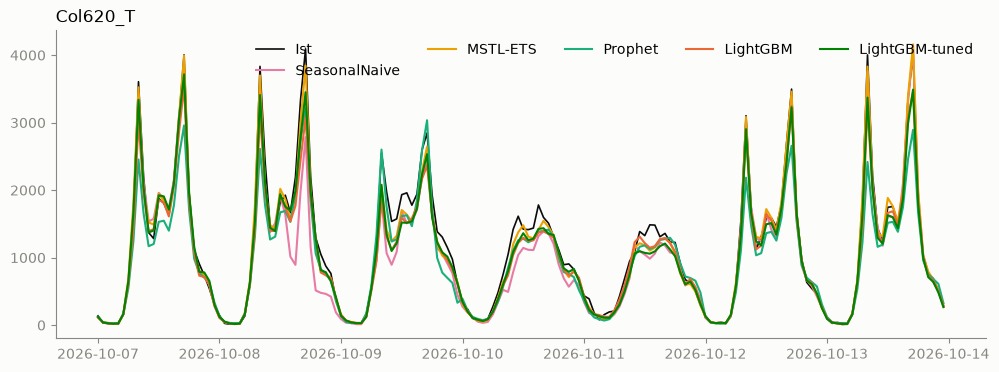

In [7]:
sensor = fc.unique_id.astype(str).mode()[0]
origin = fc.origin.unique()[-4]
week = fc[(fc.unique_id == sensor) & (fc.origin == origin) & (fc.horizon == 168)]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(week.drop_duplicates('ds').set_index('ds').y, color=INK, linewidth=1.2, label='Ist')
for m in classic:
    ax.plot(week[week.model == m].set_index('ds').yhat, color=COLORS[m], linewidth=1.5, label=m)
ax.legend(frameon=False, ncol=5)
ax.set_title(f'{sensor}', loc='left');